# Tarea 1 · Parte 1 — Recolección y limpieza de noticias de **El Comercio** (Caso B)

**Pregunta guía:** ¿Pueden convertir titulares peruanos en un clasificador de noticias?

En esta parte se construye el dataset base del clasificador: se recolectan noticias reales de El Comercio por sus **canales oficiales (RSS y sitemaps de noticias)**, se limpian, se mapean a las **4 categorías fijas** (`politica`, `economia`, `deportes`, `ciencia_tecnologia`) y se exploran con Plotly. Como extras opcionales se aplica **NER peruano** (entidades más frecuentes por categoría) y un **buscador semántico** por similitud coseno.

| Paso | Qué se hace | Resultado |
|---|---|---|
| 1 | Revisar `robots.txt` y definir las fuentes | Ficha de recolección |
| 2 | Descargar RSS + sitemaps de noticias (User-Agent propio, pausa de 1–2 s, máximo 1 reintento) | XML crudo en `datos/raw/` |
| 3 | Limpiar: vacíos, duplicados, mapeo de secciones, cupo por categoría | Tabla de mapeo + reporte de descartes |
| 4 | Completar la bajada desde la meta descripción de cada nota (solo se lee el `<head>`) | `datos/raw/meta_articulos.json` |
| 5 | EDA: 3 gráficos Plotly con títulos que expresan una conclusión + top 5 titulares | Hallazgos |
| 6 | Exportar | `datos/noticias.csv` (7 columnas) |
| 7 (extra) | NER con `mrm8488/bert-spanish-cased-finetuned-ner` | `datos/entidades_ner.csv` |
| 8 (extra) | Buscador semántico (embeddings multilingües + coseno) | `buscar()` y `datos/embeddings_noticias.npy` |

## 0. Configuración

- **Dependencias:** `requests`, `beautifulsoup4`, `lxml`, `pandas`, `plotly`, `kaleido` (PNG de los gráficos para que se vean en GitHub) y, para los extras, `torch`, `transformers` y `sentence-transformers`.
- **`USAR_CACHE = True`:** si los archivos de `datos/raw/` ya existen, el notebook se vuelve a ejecutar **sin descargar de nuevo** y produce exactamente el mismo dataset (reproducibilidad, y no se sobrecarga al medio). Con `False` se recolecta todo otra vez.

In [ ]:
import json
import random
import re
import time
from datetime import datetime
from html import unescape
from pathlib import Path
from urllib.parse import urlparse, urlunparse
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup
from IPython.display import display

# Cada gráfico se guarda interactivo (Jupyter/VS Code) y como PNG (visible en GitHub)
pio.renderers.default = "plotly_mimetype+png"
px.defaults.template = "plotly_white"
px.defaults.width, px.defaults.height = 1000, 520
pd.set_option("display.max_colwidth", 110)

MEDIO = "El Comercio"
BASE_URL = "https://elcomercio.pe"
USER_AGENT = ("TareaDiplomadoPUCP-DataSciencePython/1.0 "
              "(proyecto academico; +https://github.com/Cris92W/Python-Intermedio)")
PAUSA_MIN, PAUSA_MAX = 1.0, 2.0     # segundos entre solicitudes
TIMEOUT = 20
USAR_CACHE = True                   # reutiliza datos/raw/ si la descarga ya existe
CUPO_POR_CATEGORIA = 100            # 4 x 100 = 400 noticias (rango pedido: 350–400)
ORDEN_CAT = ["politica", "economia", "deportes", "ciencia_tecnologia"]

DATOS = Path("datos")
RAW = DATOS / "raw"
RAW.mkdir(parents=True, exist_ok=True)

SESION = requests.Session()
SESION.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
random.seed(42)

### Funciones de descarga responsable

- `pedir()`: hace el GET con el User-Agent descriptivo, **espera 1–2 s después de cada solicitud** y hace **como máximo 1 reintento** (solo ante error de red, 429 o 5xx). Cada solicitud queda anotada en `datos/raw/log_solicitudes.csv` (momento, URL, intento, estado), que sirve de evidencia de la recolección.
- `descargar()`: guarda la respuesta tal cual en `datos/raw/` (respaldo crudo) o la lee de ahí si `USAR_CACHE`.

In [ ]:
REINTENTAR = {429, 500, 502, 503, 504}
LOG_PATH = RAW / "log_solicitudes.csv"
registro = []


def pausar():
    time.sleep(random.uniform(PAUSA_MIN, PAUSA_MAX))


def pedir(url, stream=False):
    """GET con User-Agent propio, pausa de 1–2 s y como máximo 1 reintento."""
    for intento in (1, 2):                         # intento original + 1 reintento
        momento = datetime.now().isoformat(timespec="milliseconds")
        try:
            r = SESION.get(url, timeout=TIMEOUT, stream=stream)
            estado = r.status_code
        except requests.RequestException as e:
            r, estado = None, type(e).__name__
        registro.append({"momento": momento, "url": url, "intento": intento, "estado": estado})
        pausar()
        if r is not None and estado not in REINTENTAR:
            return r
    print(f"Falló tras 1 reintento ({estado}): {url}")
    return None


def guardar_registro():
    """Agrega las solicitudes hechas en esta ejecución al log de datos/raw/."""
    if registro:
        nuevo = pd.DataFrame(registro)
        previo = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else None
        pd.concat([previo, nuevo]).to_csv(LOG_PATH, index=False)
        registro.clear()


def descargar(url, destino):
    """Devuelve el contenido de `url` y lo guarda en `destino`; si USAR_CACHE y ya existe, lo lee de disco."""
    destino = Path(destino)
    if USAR_CACHE and destino.exists():
        return destino.read_bytes()
    r = pedir(url)
    if r is None or r.status_code != 200:
        print(f"Sin contenido ({None if r is None else r.status_code}): {url}")
        return b""
    destino.write_bytes(r.content)
    return r.content

## 1. Ficha de recolección y revisión de `robots.txt`

El `robots.txt` de El Comercio solo prohíbe a todos los agentes `/catalogo/`, `/buscar/` y el archivo histórico (`/archivo/todas/19*` y `/200*`), y **publica sus propios sitemaps y feeds**. Por eso no se hace scraping de portadas: se usan

- el **RSS** de cada sección (`/arc/outboundfeeds/rss/category/<seccion>/`), que trae titular, bajada y fecha;
- el **sitemap de noticias** de cada sección (`/sitemap/news/<seccion>/`), que trae hasta 100 notas recientes con titular y fecha;
- el **RSS de portada**, que mezcla todas las secciones y sirve para ilustrar el mapeo y los descartes.

Secciones objetivo: `politica`, `economia`, `deporte-total` (deportes) y `tecnologia` (ciencia y tecnología).

In [ ]:
SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]

FUENTES = {"rss_portada": f"{BASE_URL}/arc/outboundfeeds/rss/?outputType=xml"}
for s in SECCIONES:
    FUENTES[f"rss_{s}"] = f"{BASE_URL}/arc/outboundfeeds/rss/category/{s}/?outputType=xml"
    FUENTES[f"sitemap_news_{s}"] = f"{BASE_URL}/sitemap/news/{s}/?outputType=xml"

# Fecha de recolección: se registra la primera vez y se conserva al re-ejecutar con caché
META_PATH = RAW / "metadatos_recoleccion.json"
if USAR_CACHE and META_PATH.exists():
    META = json.loads(META_PATH.read_text(encoding="utf-8"))
else:
    META = {"medio": MEDIO, "base_url": BASE_URL,
            "fecha_recoleccion": datetime.now().isoformat(timespec="seconds"),
            "user_agent": USER_AGENT, "pausa_segundos": [PAUSA_MIN, PAUSA_MAX],
            "max_reintentos": 1, "fuentes": FUENTES}
    META_PATH.write_text(json.dumps(META, ensure_ascii=False, indent=2), encoding="utf-8")

robots_txt = descargar(f"{BASE_URL}/robots.txt", RAW / "robots.txt").decode("utf-8")
rp = RobotFileParser()
rp.parse(robots_txt.splitlines())

print(f"Medio: {MEDIO} | URL base: {BASE_URL}")
print(f"Fecha de recolección: {META['fecha_recoleccion']}")
print(f"User-Agent: {USER_AGENT}")
print("Reglas para todos los agentes:", [l for l in robots_txt.splitlines()[:6] if l.startswith("Disallow")])

ficha = pd.DataFrame([{"fuente": k, "url": v, "permitido_por_robots": rp.can_fetch(USER_AGENT, v)}
                      for k, v in FUENTES.items()])
ficha

Medio: El Comercio | URL base: https://elcomercio.pe
Fecha de recolección: 2026-10-17T00:17:55
User-Agent: TareaDiplomadoPUCP-DataSciencePython/1.0 (proyecto academico; +https://github.com/Cris92W/Python-Intermedio)
Reglas para todos los agentes: ['Disallow: /catalogo/', 'Disallow: /buscar/', 'Disallow: /archivo/todas/19*', 'Disallow: /archivo/todas/200*']


,fuente,url,permitido_por_robots
0,rss_portada,https://elcomercio.pe/arc/outboundfeeds/rss/?outputType=xml,True
1,rss_politica,https://elcomercio.pe/arc/outboundfeeds/rss/category/politica/?outputType=xml,True
2,sitemap_news_politica,https://elcomercio.pe/sitemap/news/politica/?outputType=xml,True
3,rss_economia,https://elcomercio.pe/arc/outboundfeeds/rss/category/economia/?outputType=xml,True
4,sitemap_news_economia,https://elcomercio.pe/sitemap/news/economia/?outputType=xml,True
5,rss_deporte-total,https://elcomercio.pe/arc/outboundfeeds/rss/category/deporte-total/?outputType=xml,True
6,sitemap_news_deporte-total,https://elcomercio.pe/sitemap/news/deporte-total/?outputType=xml,True
7,rss_tecnologia,https://elcomercio.pe/arc/outboundfeeds/rss/category/tecnologia/?outputType=xml,True
8,sitemap_news_tecnologia,https://elcomercio.pe/sitemap/news/tecnologia/?outputType=xml,True


## 2. Descarga de los feeds y respaldo crudo

Cada XML se guarda sin modificar en `datos/raw/<fuente>.xml`. Luego se extraen titular, bajada, URL y fecha de cada ítem. El sitemap de noticias no trae bajada; se completa en el paso 4.

In [ ]:
def texto_de(nodo, etiqueta):
    hijo = nodo.find(etiqueta)
    return hijo.get_text() if hijo else ""


def parsear_rss(xml, fuente):
    sopa = BeautifulSoup(xml, "xml")
    return [{"titular": texto_de(it, "title"), "bajada": texto_de(it, "description"),
             "url": texto_de(it, "link").strip(), "fecha_raw": texto_de(it, "pubDate").strip(),
             "fuente": fuente} for it in sopa.find_all("item")]


def parsear_sitemap_news(xml, fuente):
    sopa = BeautifulSoup(xml, "xml")
    return [{"titular": texto_de(u, "news:title"), "bajada": "",
             "url": texto_de(u, "loc").strip(), "fecha_raw": texto_de(u, "news:publication_date").strip(),
             "fuente": fuente} for u in sopa.find_all("url")]


filas = []
for nombre, url in FUENTES.items():
    xml = descargar(url, RAW / f"{nombre}.xml")
    parser = parsear_rss if nombre.startswith("rss") else parsear_sitemap_news
    items = parser(xml, nombre)
    filas += items
    print(f"{nombre:<28} {len(xml) / 1024:>6.0f} KB  {len(items):>4} ítems")

guardar_registro()
df_crudo = pd.DataFrame(filas)
df_crudo.to_csv(RAW / "noticias_crudas.csv", index=False, encoding="utf-8")
print(f"\nTotal crudo (con duplicados entre fuentes): {len(df_crudo)} filas → {RAW / 'noticias_crudas.csv'}")

rss_portada                    1800 KB   100 ítems
rss_politica                    451 KB    37 ítems
sitemap_news_politica           122 KB   100 ítems
rss_economia                    763 KB    97 ítems
sitemap_news_economia           118 KB   100 ítems
rss_deporte-total               475 KB    59 ítems
sitemap_news_deporte-total      142 KB   100 ítems
rss_tecnologia                  148 KB    22 ítems
sitemap_news_tecnologia         114 KB   100 ítems

Total crudo (con duplicados entre fuentes): 715 filas → datos\raw\noticias_crudas.csv


## 3. Limpieza y mapeo de secciones

1. **Normalización:** se decodifican entidades HTML, se quitan etiquetas y espacios repetidos; la URL se normaliza (https, sin parámetros) y la fecha se pasa a hora de Lima.
2. **`seccion_original`** = primer segmento de la ruta de la URL (`elcomercio.pe/<seccion>/<subseccion>/...`). Es la sección real de la nota, aunque haya llegado por el feed de otra sección.
3. Se descartan, **en este orden y registrando el motivo**: titulares vacíos o sin fecha → duplicados por URL → duplicados por titular → secciones sin categoría equivalente (no se crea una 5.ª categoría) → URLs bloqueadas por `robots.txt` → exceso sobre el cupo de 100 por categoría (se conservan las más recientes, para un dataset balanceado de máximo 400).

In [ ]:
def limpiar_texto(t):
    t = unescape(t or "")
    if "<" in t:
        t = BeautifulSoup(t, "html.parser").get_text(" ")
    return re.sub(r"\s+", " ", t).strip()


def normalizar_url(u):
    p = urlparse(u.strip())
    ruta = p.path if p.path.endswith("/") else p.path + "/"
    return urlunparse(("https", p.netloc.lower(), ruta, "", "", ""))


df = df_crudo.copy()
df["titular"] = df["titular"].map(limpiar_texto)
df["bajada"] = df["bajada"].map(limpiar_texto)
df["url"] = df["url"].map(normalizar_url)
partes = df["url"].map(lambda u: urlparse(u).path.strip("/").split("/"))
df["seccion_original"] = partes.str[0]
df["subseccion"] = partes.map(lambda p: p[1] if len(p) > 2 else "")
df["fecha"] = (pd.to_datetime(df["fecha_raw"], utc=True, format="mixed")
               .dt.tz_convert("America/Lima").dt.tz_localize(None))

descartes = []


def descartar(df, mascara, motivo):
    """Quita las filas de `mascara`, las guarda con su motivo y reporta cuántas quedan."""
    descartes.append(df.loc[mascara].assign(motivo=motivo))
    print(f"{motivo:<70} -{mascara.sum():>4} → quedan {(~mascara).sum()}")
    return df.loc[~mascara].copy()


print(f"{'Filas crudas':<70}  {len(df):>4}")
df = descartar(df, df["titular"].eq(""), "Titular vacío")
df = descartar(df, df["fecha"].isna(), "Fecha vacía o inválida")

# Duplicados por URL: se prioriza la fila del RSS (trae bajada) y se conserva la bajada no vacía de cualquier fuente
df = df.sort_values("fuente", key=lambda s: ~s.str.startswith("rss"), kind="stable")
bajada_por_url = df[df["bajada"].ne("")].groupby("url")["bajada"].first()
df = descartar(df, df.duplicated("url"), "Duplicado por URL (misma nota en RSS y sitemap, o en 2 feeds)")
df["bajada"] = df["url"].map(bajada_por_url).fillna("")

df = descartar(df, df["titular"].str.lower().duplicated(), "Duplicado por titular (misma nota con otra URL)")

Filas crudas                                                             715
Titular vacío                                                          -   0 → quedan 715
Fecha vacía o inválida                                                 -   0 → quedan 715
Duplicado por URL (misma nota en RSS y sitemap, o en 2 feeds)          - 218 → quedan 497
Duplicado por titular (misma nota con otra URL)                        -   0 → quedan 497


### Tabla de mapeo `seccion_original` → categoría

Solo se mapean secciones cuyo contenido corresponde sin ambigüedad a una de las 4 categorías. `elecciones` es una sección propia de El Comercio para la cobertura electoral 2026, por eso va a `politica`. Las secciones mixtas (mundo, opinión, explicativos, datos, entretenimiento) se descartan y se reportan.

In [ ]:
MAPEO = {
    "politica":      ("politica",           "Sección de política nacional (gobierno, congreso, partidos)"),
    "elecciones":    ("politica",           "Especial de cobertura electoral 2026: tema político"),
    "economia":      ("economia",           "Sección de economía (Perú, mercados, Día 1, mundo)"),
    "deporte-total": ("deportes",           "Marca deportiva de El Comercio (fútbol, polideportivo, etc.)"),
    "tecnologia":    ("ciencia_tecnologia", "Incluye subsecciones ciencias, IA, ciberseguridad, ecología, gadgets"),
}
NO_MAPEADAS = {
    "mundo": "Internacional: mezcla política exterior, sucesos y sociedad",
    "mag": "Entretenimiento y contenido viral",
    "respuestas": "Explicativos de temas variados (trámites, feriados, etc.)",
    "lima": "Noticias locales y sucesos",
    "peru": "Noticias regionales y sucesos",
    "luces": "Cultura y espectáculos",
    "tvmas": "Televisión y espectáculos",
    "opinion": "Columnas de opinión de temas mixtos",
    "ecdata": "Periodismo de datos de temas mixtos",
}

tabla_mapeo = df.groupby("seccion_original").size().rename("noticias").reset_index()
tabla_mapeo["categoria"] = tabla_mapeo["seccion_original"].map(lambda s: MAPEO[s][0] if s in MAPEO else "— descartada")
tabla_mapeo["criterio"] = tabla_mapeo["seccion_original"].map(
    lambda s: MAPEO[s][1] if s in MAPEO else NO_MAPEADAS.get(s, "Sin equivalente en las 4 categorías"))
tabla_mapeo = tabla_mapeo.sort_values(["categoria", "noticias"], ascending=[True, False]).reset_index(drop=True)
display(tabla_mapeo)

df["etiqueta"] = df["seccion_original"].map(lambda s: MAPEO[s][0] if s in MAPEO else None)
df = descartar(df, df["etiqueta"].isna(), "Sección sin categoría equivalente (no se crea una 5.ª)")
df = descartar(df, ~df["url"].map(lambda u: rp.can_fetch(USER_AGENT, u)), "URL bloqueada por robots.txt")

orden_reciente = df.groupby("etiqueta")["fecha"].rank(method="first", ascending=False)
df = descartar(df, orden_reciente > CUPO_POR_CATEGORIA,
               f"Excede el cupo de {CUPO_POR_CATEGORIA} por categoría (se conservan las más recientes)")
df["etiqueta"].value_counts()

,seccion_original,noticias,categoria,criterio
0,tecnologia,95,ciencia_tecnologia,"Incluye subsecciones ciencias, IA, ciberseguridad, ecología, gadgets"
1,deporte-total,99,deportes,"Marca deportiva de El Comercio (fútbol, polideportivo, etc.)"
2,economia,114,economia,"Sección de economía (Perú, mercados, Día 1, mundo)"
3,politica,92,politica,"Sección de política nacional (gobierno, congreso, partidos)"
4,elecciones,19,politica,Especial de cobertura electoral 2026: tema político
5,mag,28,— descartada,Entretenimiento y contenido viral
6,respuestas,14,— descartada,"Explicativos de temas variados (trámites, feriados, etc.)"
7,mundo,8,— descartada,"Internacional: mezcla política exterior, sucesos y sociedad"
8,opinion,8,— descartada,Columnas de opinión de temas mixtos
9,ecdata,5,— descartada,Periodismo de datos de temas mixtos


Sección sin categoría equivalente (no se crea una 5.ª)                 -  78 → quedan 419
URL bloqueada por robots.txt                                           -   0 → quedan 419
Excede el cupo de 100 por categoría (se conservan las más recientes)   -  25 → quedan 394


etiqueta
politica              100
economia              100
deportes               99
ciencia_tecnologia     95
Name: count, dtype: int64

## 4. Completar la bajada desde cada nota

Las notas que llegaron solo por el sitemap no traen bajada. Para ellas se pide la página y **se lee únicamente hasta `</head>`** (≈150 KB en vez de ≈650 KB), de donde se toma `<meta name="description">`, que es la bajada que publica el medio. Esto además **verifica que la URL funcione** (HTTP 200). Las respuestas se guardan en `datos/raw/meta_articulos.json`, así que al re-ejecutar no se vuelve a pedir nada.

In [ ]:
META_ART = RAW / "meta_articulos.json"
meta_art = json.loads(META_ART.read_text(encoding="utf-8")) if USAR_CACHE and META_ART.exists() else {}


def leer_meta_articulo(url):
    """Descarga solo el <head> de la nota y devuelve el HTTP status y la meta descripción."""
    r = pedir(url, stream=True)
    if r is None:
        return {"status": None, "bajada": ""}
    contenido = b""
    for bloque in r.iter_content(32_768):
        contenido += bloque
        if b"</head>" in contenido or len(contenido) > 1_000_000:
            break
    r.close()
    head = BeautifulSoup(contenido.decode("utf-8", errors="replace"), "lxml")
    meta = (head.find("meta", attrs={"name": "description"})
            or head.find("meta", attrs={"property": "og:description"}))
    return {"status": r.status_code, "bajada": limpiar_texto(meta.get("content", "")) if meta else ""}


pendientes = [u for u in df.loc[df["bajada"].eq(""), "url"] if u not in meta_art]
print(f"Notas sin bajada: {df['bajada'].eq('').sum()} | por descargar ahora: {len(pendientes)}")
inicio = time.time()
for i, url in enumerate(pendientes, 1):
    meta_art[url] = leer_meta_articulo(url)
    if i % 25 == 0 or i == len(pendientes):
        print(f"  {i}/{len(pendientes)} ({time.time() - inicio:.0f} s)")
        META_ART.write_text(json.dumps(meta_art, ensure_ascii=False, indent=1), encoding="utf-8")
        guardar_registro()

sin_bajada = df["bajada"].eq("")
df.loc[sin_bajada, "bajada"] = df.loc[sin_bajada, "url"].map(lambda u: meta_art[u]["bajada"])
df["visitada"] = df["url"].isin(meta_art.keys())
df["http_status"] = df["url"].map(lambda u: meta_art.get(u, {}).get("status"))
df = descartar(df, df["visitada"] & df["http_status"].ne(200), "URL no responde HTTP 200")
print(f"Bajadas completadas desde la página: {sin_bajada.sum()} | siguen vacías: {df['bajada'].eq('').sum()}")

Notas sin bajada: 222 | por descargar ahora: 0
URL no responde HTTP 200                                               -   0 → quedan 394
Bajadas completadas desde la página: 222 | siguen vacías: 0


### Verificación de URLs del RSS (muestra)

Las notas con bajada del RSS no se visitaron. Se verifica una **muestra aleatoria de 20** (`random_state=42`) para comprobar que las URLs del CSV son funcionales.

In [ ]:
VERIF = RAW / "verificacion_urls.json"
verif = json.loads(VERIF.read_text(encoding="utf-8")) if USAR_CACHE and VERIF.exists() else {}
muestra = df.loc[~df["visitada"]].sample(20, random_state=42)["url"]
for url in muestra:
    if url not in verif:
        r = pedir(url, stream=True)
        verif[url] = None if r is None else r.status_code
        if r is not None:
            r.close()
VERIF.write_text(json.dumps(verif, indent=1), encoding="utf-8")
guardar_registro()

estado_muestra = muestra.map(verif)
print("HTTP status en la muestra:", estado_muestra.value_counts(dropna=False).to_dict())
en_muestra = df["url"].isin(muestra)
df.loc[en_muestra, "visitada"] = True
df.loc[en_muestra, "http_status"] = df.loc[en_muestra, "url"].map(verif)
df = descartar(df, en_muestra & df["http_status"].ne(200), "URL no responde HTTP 200 (muestra RSS)")

HTTP status en la muestra: {200: 20}
URL no responde HTTP 200 (muestra RSS)                                 -   0 → quedan 394


### Registro de solicitudes (evidencia de recolección responsable)

Resumen de `datos/raw/log_solicitudes.csv`: cuántas solicitudes se hicieron, con qué resultado y cuánto tiempo pasó entre una y otra (incluye la pausa de 1–2 s más el tiempo de respuesta).

In [ ]:
log = pd.read_csv(LOG_PATH, parse_dates=["momento"]).sort_values("momento")
intervalos = log["momento"].diff().dt.total_seconds()
intervalos = intervalos[intervalos < 60]          # excluye saltos entre sesiones distintas
print(f"Solicitudes HTTP: {len(log)} | reintentos: {(log['intento'] == 2).sum()} | "
      f"periodo: {log['momento'].min():%Y-%m-%d %H:%M} a {log['momento'].max():%H:%M}")
print("Estados:", log["estado"].astype(str).value_counts().to_dict())
print(f"Segundos entre solicitudes consecutivas: mín {intervalos.min():.2f} | "
      f"mediana {intervalos.median():.2f} | máx {intervalos.max():.2f}")

Solicitudes HTTP: 252 | reintentos: 0 | periodo: 2026-10-17 00:17 a 00:30
Estados: {'200': 252}
Segundos entre solicitudes consecutivas: mín 1.34 | mediana 2.92 | máx 11.33


### Reporte de noticias descartadas

Todas las filas eliminadas quedan en `datos/descartes.csv` con su motivo. Los duplicados no son noticias perdidas (la nota se conserva una vez); los descartes de contenido real son las secciones sin categoría y el exceso sobre el cupo.

In [ ]:
reporte = pd.concat(descartes, ignore_index=True)
reporte[["motivo", "seccion_original", "titular", "url", "fuente"]].to_csv(
    DATOS / "descartes.csv", index=False, encoding="utf-8")

resumen_descartes = (reporte.groupby("motivo", sort=False).size().rename("filas").reset_index())
display(resumen_descartes)

print("Secciones descartadas por no tener categoría equivalente:")
sin_cat = reporte[reporte["motivo"].str.startswith("Sección sin")]
display(sin_cat.groupby("seccion_original").agg(noticias=("url", "size"), ejemplo=("titular", "first"))
        .sort_values("noticias", ascending=False))

,motivo,filas
0,"Duplicado por URL (misma nota en RSS y sitemap, o en 2 feeds)",218
1,Sección sin categoría equivalente (no se crea una 5.ª),78
2,Excede el cupo de 100 por categoría (se conservan las más recientes),25


Secciones descartadas por no tener categoría equivalente:


,noticias,ejemplo
seccion_original,,
mag,28,Seguro Social aumentará en 2027: cuándo llegarán los pagos con hasta US$75 más al mes
respuestas,14,Luto en la televisión: fallece querido actor de ‘Pasión de Gavilanes’ y ‘La Reina del Sur’
mundo,8,Efemérides del 17 de octubre: ¿Qué pasó en el mundo un día como hoy?
opinion,8,El costo invisible de la desinformación en salud
ecdata,5,Fenómeno El Niño: 9 de los 18 distritos limeños más vulnerables están retrasados en el gasto para desastres
lima,4,San Isidro ofrece clases gratuitas de adiestramiento canino con temática de Halloween
bbc-news-mundo,2,"Qué pasó con el experimento de Bukele de convertir a El Salvador en el ""país del bitcoin"""
luces,2,"Horóscopo de hoy, sábado 17 de octubre: Lee aquí tus predicciones"
ruedas-tuercas,2,Tesla Roadster: Elon Musk presentó un carro eléctrico que puede “volar” y acelerar de 0 a 100 km/h en meno...


## 5. Análisis exploratorio (EDA)

Los títulos de los gráficos se calculan a partir de los datos, para que la conclusión escrita siempre coincida con lo que se ve.

In [ ]:
df = df.sort_values("fecha", ascending=False).reset_index(drop=True)
df["medio"] = MEDIO
df["n_palabras"] = df["titular"].str.split().str.len()
df["n_caracteres"] = df["titular"].str.len()
df["dia"] = df["fecha"].dt.normalize()
df["subseccion_g"] = df["subseccion"].replace("", "(portada de sección)")

print(f"Noticias finales: {len(df)}")
print(f"Rango de fechas: {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
df["etiqueta"].value_counts().to_frame("noticias")

Noticias finales: 394
Rango de fechas: 2026-10-06 a 2026-10-17


,noticias
etiqueta,
politica,100
economia,100
deportes,99
ciencia_tecnologia,95


### Gráfico 1 — Composición del dataset por categoría y subsección

Resorting to unclean kill browser.


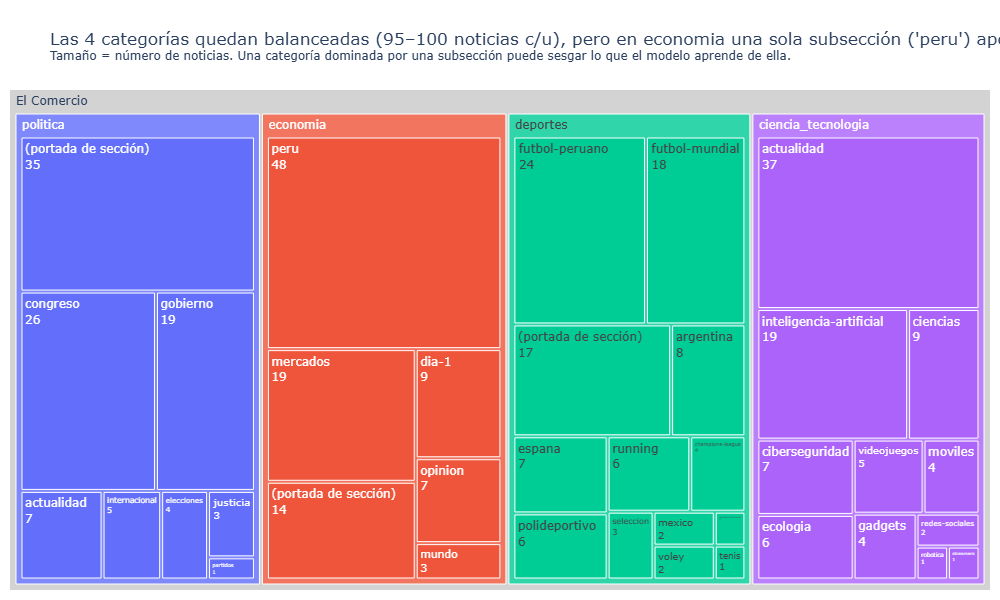

In [ ]:
por_cat = df["etiqueta"].value_counts()
top_sub = (df.groupby(["etiqueta", "subseccion_g"]).size().rename("n").reset_index()
           .sort_values("n", ascending=False).drop_duplicates("etiqueta").set_index("etiqueta"))
top_sub["peso"] = top_sub["n"] / por_cat
cat_conc = top_sub["peso"].idxmax()

titulo = (f"Las 4 categorías quedan balanceadas ({por_cat.min()}–{por_cat.max()} noticias c/u), pero en {cat_conc} "
          f"una sola subsección ('{top_sub.loc[cat_conc, 'subseccion_g']}') aporta el {top_sub.loc[cat_conc, 'peso']:.0%}"
          "<br><sup>Tamaño = número de noticias. Una categoría dominada por una subsección puede sesgar lo que el modelo aprende de ella.</sup>")
fig = px.treemap(df, path=[px.Constant(MEDIO), "etiqueta", "subseccion_g"], title=titulo, height=600)
fig.update_traces(textinfo="label+value", root_color="lightgrey")
fig.update_layout(margin=dict(t=90, l=10, r=10, b=10))
fig.show()

### Gráfico 2 — Longitud de los titulares por categoría

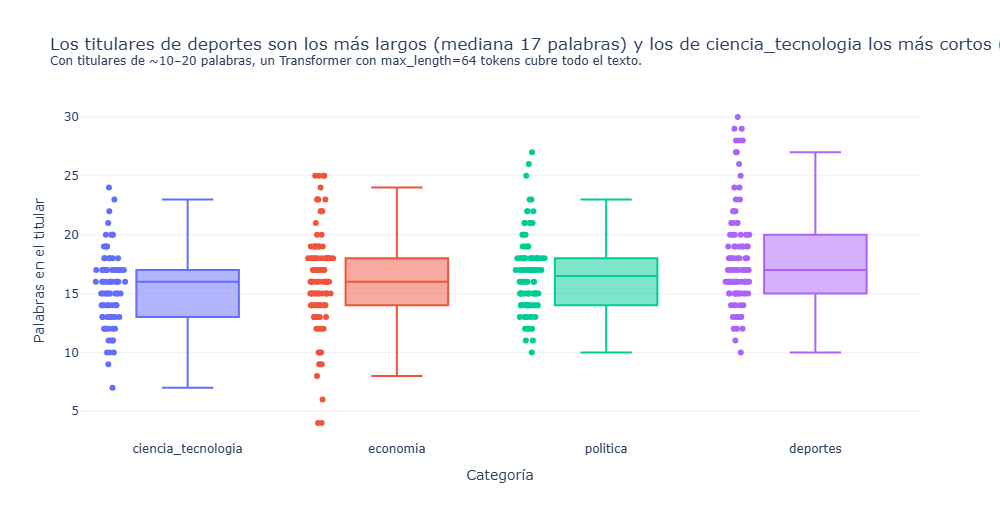

In [ ]:
medianas = df.groupby("etiqueta")["n_palabras"].median().sort_values()
titulo = (f"Los titulares de {medianas.index[-1]} son los más largos (mediana {medianas.iloc[-1]:.0f} palabras) "
          f"y los de {medianas.index[0]} los más cortos ({medianas.iloc[0]:.0f})"
          "<br><sup>Con titulares de ~10–20 palabras, un Transformer con max_length=64 tokens cubre todo el texto.</sup>")
fig = px.box(df, x="etiqueta", y="n_palabras", color="etiqueta", points="all",
             category_orders={"etiqueta": list(medianas.index)}, hover_data=["titular"],
             labels={"n_palabras": "Palabras en el titular", "etiqueta": "Categoría"}, title=titulo)
fig.update_layout(showlegend=False)
fig.show()

### Gráfico 3 — Cobertura temporal por categoría

Resorting to unclean kill browser.


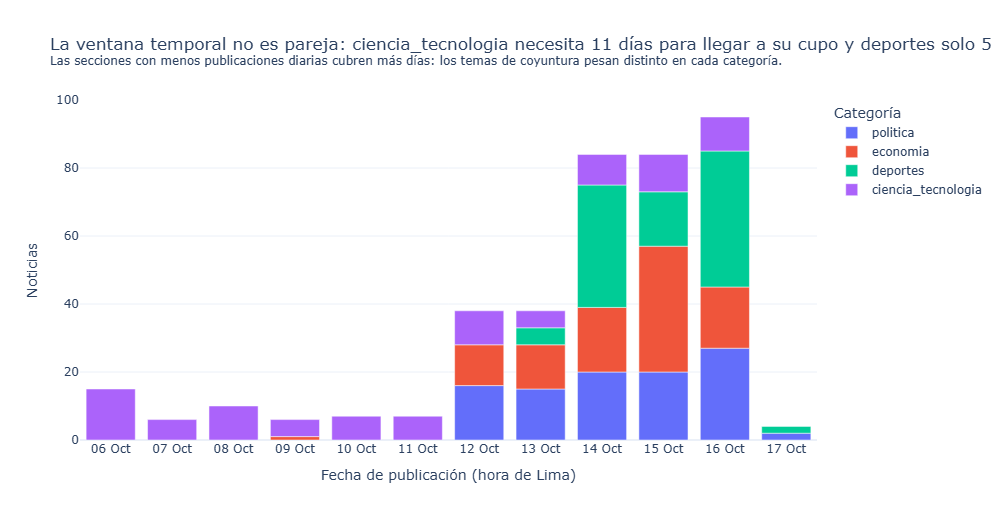

In [ ]:
dias_cubiertos = df.groupby("etiqueta")["dia"].agg(lambda s: (s.max() - s.min()).days + 1).sort_values()
por_dia = df.groupby(["dia", "etiqueta"]).size().rename("noticias").reset_index()
titulo = (f"La ventana temporal no es pareja: {dias_cubiertos.index[-1]} necesita {dias_cubiertos.iloc[-1]} días para llegar "
          f"a su cupo y {dias_cubiertos.index[0]} solo {dias_cubiertos.iloc[0]}"
          "<br><sup>Las secciones con menos publicaciones diarias cubren más días: los temas de coyuntura pesan distinto en cada categoría.</sup>")
fig = px.bar(por_dia, x="dia", y="noticias", color="etiqueta", title=titulo, category_orders={"etiqueta": ORDEN_CAT},
             labels={"dia": "Fecha de publicación (hora de Lima)", "noticias": "Noticias", "etiqueta": "Categoría"})
fig.update_xaxes(dtick="D1", tickformat="%d %b")
fig.show()

### Top 5 titulares más largos y más cortos

In [ ]:
cols = ["n_caracteres", "n_palabras", "etiqueta", "titular"]
print("Top 5 titulares MÁS LARGOS")
display(df.nlargest(5, "n_caracteres")[cols].reset_index(drop=True))
print("Top 5 titulares MÁS CORTOS")
display(df.nsmallest(5, "n_caracteres")[cols].reset_index(drop=True))

Top 5 titulares MÁS LARGOS


,n_caracteres,n_palabras,etiqueta,titular
0,173,28,deportes,"Annia Cillóniz líder en su categoría en Caminos del Inca: “A veces nos toca esforzarnos el doble, pero com..."
1,171,29,deportes,"“Con Mano Menezes el mejor jugador de la selección ha sido un ecuatoriano”: Bruno Cavassa, Coki Gonzales, ..."
2,166,23,politica,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribu..."
3,160,27,deportes,"“El día de mañana me encantaría ver a tantas niñas entrando al automovilismo”: Annia Cillóniz, líder en la..."
4,160,26,politica,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no es..."


Top 5 titulares MÁS CORTOS


,n_caracteres,n_palabras,etiqueta,titular
0,22,4,economia,Invocación por el Perú
1,24,4,economia,IA y Sandbox regulatorio
2,41,8,economia,La evolución de la confianza en los pagos
3,46,6,economia,La gloria gastronómica que debemos multiplicar
4,54,9,economia,El fenómeno de El Niño y nuestros desafíos energéticos


## 6. Exportación de `datos/noticias.csv`

Se exportan exactamente las 7 columnas pedidas. `etiqueta` es la categoría derivada de la sección (etiqueta "de origen"); en la Parte 2 se compara contra el etiquetado del LLM y del Transformer.

In [ ]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = df[COLUMNAS].copy()
noticias["fecha"] = noticias["fecha"].dt.strftime("%Y-%m-%d %H:%M")
noticias.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")

# Comprobaciones del entregable
assert noticias.shape[1] == 7 and 350 <= len(noticias) <= 400
assert noticias["url"].is_unique and noticias["titular"].ne("").all()
assert set(noticias["etiqueta"]) == {"politica", "economia", "deportes", "ciencia_tecnologia"}

print("df.shape:", noticias.shape)
noticias.head()

df.shape: (394, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,"Físico, compromiso y entorno: las razones que alejaron a Piero Cari de Pablo Guede y por qué hoy Alianza v...",El futbolista de 18 años jugó apenas 154 minutos oficiales con Alianza Lima esta temporada y no era consid...,El Comercio,deporte-total,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-lima-fisico-compromiso-y-entorno-las-razones-qu...,2026-10-17 00:02,deportes
1,"De Kluiverth en Alianza a Osorio de la ‘U’: la Liga 1 vendió 18 promesas a Europa desde 2020, pero casi la...",Desde la venta de Kluiverth Aguilar en 2020 hasta el reciente fichaje de Sebastián Osorio por Sporting de ...,El Comercio,deporte-total,https://elcomercio.pe/deporte-total/futbol-peruano/alianza-lima-de-kluiverth-aguilar-en-alianza-a-sebastia...,2026-10-17 00:01,deportes
2,Renovación Popular se declara en reorganización partidaria: ¿A qué se debe y cuáles son los alcances de la...,"La medida deja sin efecto las credenciales de los coordinadores regionales, provinciales y distritales, cu...",El Comercio,politica,https://elcomercio.pe/politica/renovacion-popular-se-declara-en-reorganizacion-partidaria-a-que-se-debe-y-...,2026-10-17 00:01,politica
3,Facultades legislativas: Senado sigue sin alcanzar consenso y debate continúa entrampado,El pedido de facultades legislativas del Ejecutivo continúa entrampado en el Senado por falta de consenso....,El Comercio,politica,https://elcomercio.pe/politica/facultades-legislativas-senado-sigue-sin-alcanzar-consenso-y-debate-continu...,2026-10-17 00:01,politica
4,Los Chankas derrotó 2-1 a ADT por la fecha 12 del Torneo Clausura de la Liga 1 2026,Los Chankas se impuso por 2-1 ante ADT en un partido correspondiente a la fecha 12 del Torneo Clausura de ...,El Comercio,deporte-total,https://elcomercio.pe/deporte-total/futbol-peruano/chankas-vs-adt-en-vivo-hora-y-donde-ver-la-fecha-12-del...,2026-10-16 23:56,deportes


## 7. Extra — NER peruano: entidades más frecuentes por categoría

Se usa `mrm8488/bert-spanish-cased-finetuned-ner` (BETO ajustado en CoNLL-2002 español), que reconoce **PER** (personas), **ORG** (organizaciones), **LOC** (lugares) y **MISC**.

- Texto de entrada: `titular + ". " + bajada` (la bajada suele nombrar al político o la institución que el titular solo insinúa).
- `aggregation_strategy="first"`: cada palabra toma la etiqueta de su primer sub-token. Con `"simple"` el modelo partía palabras peruanas poco frecuentes (`Petro` + `##perú`, `Min` + `##em`); con `"first"` salen completas (*Petroperú*, *Minem*).
- Se conservan entidades con `score ≥ 0.60` y se cuentan **una vez por noticia** (frecuencia = nº de noticias que la mencionan).
- **Lectura:** PER en `politica` ≈ *políticos*; ORG en `politica` ≈ *instituciones*; ORG en `economia` ≈ *empresas e instituciones económicas* (el modelo no distingue empresa de institución).

In [ ]:
from transformers import pipeline
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()      # oculta avisos de carga de pesos
hf_logging.disable_progress_bar()

ner = pipeline("ner", model="mrm8488/bert-spanish-cased-finetuned-ner", aggregation_strategy="first")


def limpiar_entidad(t):
    t = t.replace(" ##", "").replace("##", "")
    return re.sub(r"\s+", " ", t).strip(" \"'“”‘’«».,:;()¿?¡!-")


textos = (df["titular"] + ". " + df["bajada"]).tolist()
inicio = time.time()
salidas = ner(textos, batch_size=16)
print(f"NER sobre {len(textos)} textos en {time.time() - inicio:.0f} s")

ents = pd.DataFrame([
    {"url": url, "etiqueta": etq, "tipo": e["entity_group"], "entidad": limpiar_entidad(e["word"]),
     "score": round(float(e["score"]), 3)}
    for url, etq, lista in zip(df["url"], df["etiqueta"], salidas) for e in lista
])
ents = ents[(ents["score"] >= 0.60) & (ents["entidad"].str.len() >= 2)]
ents = ents.drop_duplicates(["url", "tipo", "entidad"])
ents.to_csv(DATOS / "entidades_ner.csv", index=False, encoding="utf-8")

print(f"Entidades únicas por noticia: {len(ents)}")
pd.crosstab(ents["etiqueta"], ents["tipo"], margins=True, margins_name="total")

c:\Users\Alone PC\.conda\envs\webscraping\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NER sobre 394 textos en 140 s
Entidades únicas por noticia: 1669


tipo,LOC,MISC,ORG,PER,total
etiqueta,,,,,
ciencia_tecnologia,48,117,82,44,291
deportes,58,144,174,92,468
economia,83,103,169,42,397
politica,46,112,262,93,513
total,235,476,687,271,1669


In [ ]:
def top_entidades(etiqueta, tipo, n=10):
    sub = ents[(ents["etiqueta"] == etiqueta) & (ents["tipo"] == tipo)]
    return sub["entidad"].value_counts().head(n)


lectura = {
    "Políticos (PER · politica)": top_entidades("politica", "PER"),
    "Instituciones (ORG · politica)": top_entidades("politica", "ORG"),
    "Empresas / instituciones económicas (ORG · economia)": top_entidades("economia", "ORG"),
    "Deportistas y clubes (PER+ORG · deportes)": ents[(ents["etiqueta"] == "deportes")
                                                       & ents["tipo"].isin(["PER", "ORG"])]["entidad"].value_counts().head(10),
    "Empresas tecnológicas (ORG · ciencia_tecnologia)": top_entidades("ciencia_tecnologia", "ORG"),
}
tabla_ner = pd.DataFrame({k: [f"{e} ({n})" for e, n in v.items()] + [""] * (10 - len(v)) for k, v in lectura.items()})
tabla_ner.index = range(1, 11)
tabla_ner

,Políticos (PER · politica),Instituciones (ORG · politica),Empresas / instituciones económicas (ORG · economia),Deportistas y clubes (PER+ORG · deportes),Empresas tecnológicas (ORG · ciencia_tecnologia)
1,Keiko Fujimori (11),ONPE (17),Estados Unidos (6),Universitario (9),Google (6)
2,Carlos Mesía (7),Senado (17),MEF (5),Alianza Lima (9),Apple (4)
3,César Astudillo (5),Comisión de Constitución del Senado (14),Indecopi (4),Real Madrid (8),IA (3)
4,León XIV (4),Congreso (13),Gobierno (4),Boca Juniors (5),Microsoft (3)
5,Álvaro Vargas Llosa (4),Comisión de Constitución (13),Ministerio de Economía y Finanzas (3),ONLINE (5),Estados Unidos (3)
6,Alfonso López Chau (3),Cámara de Diputados (12),Interseguro (3),Roma (4),Estado (3)
7,Graciela Chipana (3),Ejecutivo (10),WTTC (3),Barcelona (4),IceCube (2)
8,Francis Allison (3),Ahora Nación (7),Irán (2),Perú (4),OpenAI (2)
9,Daniel Barragán (3),Fuerza Popular (7),ProInversión (2),Palmeiras (4),Nvidia (2)
10,Rafael López Aliaga (3),Renovación Popular (7),RPP (2),AS Roma (4),World Wildlife Fund (1)


Resorting to unclean kill browser.


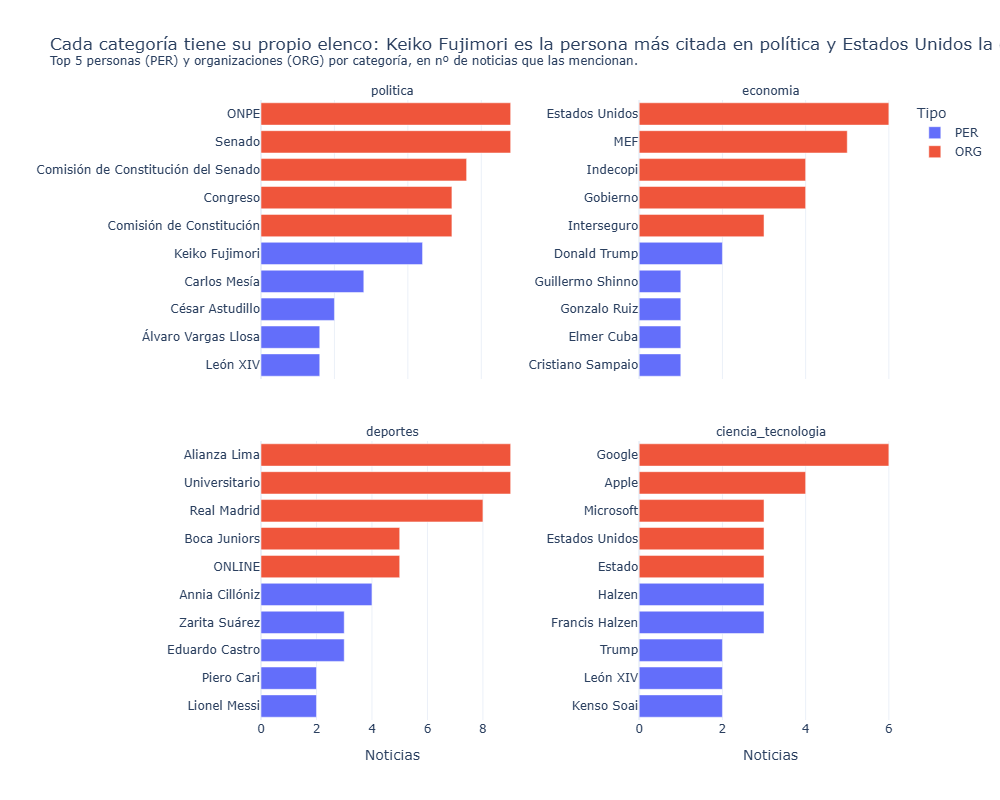

In [ ]:
top = (ents[ents["tipo"].isin(["PER", "ORG"])]
       .groupby(["etiqueta", "tipo", "entidad"]).size().rename("noticias").reset_index()
       .sort_values("noticias", ascending=False).groupby(["etiqueta", "tipo"]).head(5))

per_pol = top_entidades("politica", "PER", 1)
org_eco = top_entidades("economia", "ORG", 1)
titulo = (f"Cada categoría tiene su propio elenco: {per_pol.index[0]} es la persona más citada en política "
          f"y {org_eco.index[0]} la organización más citada en economía"
          "<br><sup>Top 5 personas (PER) y organizaciones (ORG) por categoría, en nº de noticias que las mencionan.</sup>")
fig = px.bar(top.sort_values("noticias"), x="noticias", y="entidad", color="tipo", orientation="h",
             facet_col="etiqueta", facet_col_wrap=2, facet_col_spacing=0.18, facet_row_spacing=0.1,
             category_orders={"etiqueta": ORDEN_CAT},
             height=800, title=titulo, labels={"noticias": "Noticias", "entidad": "", "tipo": "Tipo"})
fig.update_yaxes(matches=None, showticklabels=True, categoryorder="total ascending")
fig.update_xaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

## 8. Extra — Buscador semántico por similitud coseno

Cada noticia (`titular + bajada`) se convierte en un vector de 384 dimensiones con `paraphrase-multilingual-MiniLM-L12-v2` (Sentence-Transformers, entrenado para que frases con el mismo significado queden cerca). Con vectores normalizados, la **similitud coseno** es el producto punto:

$$\cos(q, d) = \frac{q \cdot d}{\lVert q\rVert\,\lVert d\rVert} = q \cdot d \quad (\text{si } \lVert q\rVert = \lVert d\rVert = 1)$$

A diferencia de buscar palabras exactas, encuentra notas relacionadas aunque usen otros términos. Los vectores se guardan en `datos/embeddings_noticias.npy` (mismo orden de filas que `noticias.csv`) para reutilizarlos en el dashboard.

In [ ]:
from sentence_transformers import SentenceTransformer

MODELO_EMB = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
modelo_emb = SentenceTransformer(MODELO_EMB)

corpus = (df["titular"] + ". " + df["bajada"]).tolist()
EMB = modelo_emb.encode(corpus, batch_size=32, normalize_embeddings=True, show_progress_bar=False)
np.save(DATOS / "embeddings_noticias.npy", EMB)
print("Matriz de embeddings:", EMB.shape)


def buscar(consulta, k=5, categoria=None):
    """Devuelve las k noticias más similares (coseno) a `consulta`; opcionalmente filtra por categoría."""
    q = modelo_emb.encode([consulta], normalize_embeddings=True)[0]
    res = df.assign(similitud=EMB @ q)
    if categoria:
        res = res[res["etiqueta"] == categoria]
    return res.nlargest(k, "similitud")[["similitud", "etiqueta", "titular", "url"]].round(3).reset_index(drop=True)


buscar("minería informal y formalización de mineros")

Matriz de embeddings: (394, 384)


,similitud,etiqueta,titular,url
0,0.500,politica,Ministro Guillermo Shinno presenta propuesta de nueva Ley Mape para formalización de mineros pequeños y ar...,https://elcomercio.pe/politica/gobierno/reinfo-ministro-guillermo-shinno-presenta-propuesta-de-nueva-ley-m...
1,0.477,economia,"Formalización minera podría aportar 1,5% adicional al PBI y generar hasta 400.000 empleos",https://elcomercio.pe/economia/peru/formalizacion-minera-podria-aportar-15-adicional-al-pbi-y-generar-hast...
2,0.456,ciencia_tecnologia,Perú: más de 200 operativos en el año en Madre de Dios no logran frenar el avance de la minería ilegal en ...,https://elcomercio.pe/tecnologia/ecologia/peru-mas-de-200-operativos-en-el-ano-en-madre-de-dios-no-logran-...
3,0.431,economia,Biministro de Economía y Minería de Chile: “Al 2035 casi toda la nueva oferta de cobre del planeta saldrá ...,https://elcomercio.pe/economia/peru/biministro-de-economia-y-mineria-de-chile-hacia-2035-practicamente-tod...
4,0.366,politica,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ¿que otras medidas in...,https://elcomercio.pe/politica/gobierno/el-proyecto-de-ley-mape-del-gobierno-desde-la-fiscalizacion-a-las-...


**Evaluación rápida del buscador:** para consultas cuyo tema pertenece claramente a una categoría, se mide qué fracción de los 5 primeros resultados cae en esa categoría (precisión@5). Las consultas no repiten palabras exactas de los titulares.

In [ ]:
consultas = {
    "resultados de las elecciones municipales y regionales": "politica",
    "denuncias contra congresistas": "politica",
    "precio del dólar y tipo de cambio": "economia",
    "inversión privada y crecimiento del PBI": "economia",
    "partido de la selección peruana": "deportes",
    "campeonato de fútbol europeo": "deportes",
    "avances de la inteligencia artificial": "ciencia_tecnologia",
    "ataques informáticos y robo de datos": "ciencia_tecnologia",
}
evaluacion = []
for consulta, esperada in consultas.items():
    res = buscar(consulta, k=5)
    evaluacion.append({"consulta": consulta, "categoria_esperada": esperada,
                       "precision@5": (res["etiqueta"] == esperada).mean(),
                       "sim_top1": res.loc[0, "similitud"], "titular_top1": res.loc[0, "titular"]})
evaluacion = pd.DataFrame(evaluacion)
print(f"Precisión@5 promedio: {evaluacion['precision@5'].mean():.0%}")
evaluacion

Precisión@5 promedio: 92%


,consulta,categoria_esperada,precision@5,sim_top1,titular_top1
0,resultados de las elecciones municipales y regionales,politica,1.0,0.810,Elecciones Regionales y Municipales 2026: resultados oficiales de ONPE en la región de Apurímac
1,denuncias contra congresistas,politica,1.0,0.646,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en grupos del Congreso
2,precio del dólar y tipo de cambio,economia,1.0,0.701,Precio del dólar del lunes 12 de octubre: a cuánto cerró el tipo de cambio
3,inversión privada y crecimiento del PBI,economia,1.0,0.547,"INEI: producción nacional presenta un crecimiento de 3,23% en agosto del 2026"
4,partido de la selección peruana,deportes,1.0,0.733,Amistosos ante Bolivia y Honduras: ¿Por qué decidieron esos rivales y cuáles son los planes de Menezes par...
5,campeonato de fútbol europeo,deportes,1.0,0.666,"Goles de UEFA Champions League hoy, miércoles 14 de octubre: resumen y resultados de la fecha 2"
6,avances de la inteligencia artificial,ciencia_tecnologia,0.6,0.688,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas
7,ataques informáticos y robo de datos,ciencia_tecnologia,0.8,0.630,Ciberamenazas en América Latina: Perú registró mayor actividad de malware en el primer semestre de 2026


In [ ]:
# Búsqueda restringida a una categoría
buscar("empresas peruanas que exportan", k=5, categoria="economia")

,similitud,etiqueta,titular,url
0,0.689,economia,Adex destaca que el nuevo embajador de Perú en Estados Unidos incluya la eliminación de aranceles a las ex...,https://elcomercio.pe/economia/peru/adex-destaca-que-el-nuevo-embajador-de-peru-en-estados-unidos-incluya-...
1,0.682,economia,Promperú impulsa reinversión de empresas extranjeras en el país a través del Perú Investment Round Table 2026,https://elcomercio.pe/economia/peru/promperu-impulsa-reinversion-de-empresas-extranjeras-en-el-pais-a-trav...
2,0.679,economia,La gloria gastronómica que debemos multiplicar,https://elcomercio.pe/economia/opinion/la-gloria-gastronomica-que-debemos-multiplicar-noticia/
3,0.679,economia,"Luis Felipe Gazitúa, del Consejo Empresarial Chileno- Peruano: “El principal destino de la inversión extra...",https://elcomercio.pe/economia/luis-felipe-gazitua-el-principal-destino-de-la-inversion-extranjera-chilena...
4,0.612,economia,"Beatriz Boza, socia y líder de Familias Empresarias en EY: “La siguiente gran apuesta de los empresarios p...",https://elcomercio.pe/economia/beatriz-boza-la-siguiente-gran-apuesta-de-los-empresarios-peruanos-no-es-cr...


## 9. Resumen de la Parte 1

In [ ]:
print(f"Medio: {MEDIO} | recolección: {META['fecha_recoleccion']} | fuentes: {len(FUENTES)} feeds/sitemaps")
print(f"Filas crudas: {len(df_crudo)} → noticias finales: {len(noticias)}")
print("Por categoría:", noticias["etiqueta"].value_counts().to_dict())
print("Descartes por motivo:", resumen_descartes.set_index("motivo")["filas"].to_dict())
print(f"Bajadas vacías: {noticias['bajada'].eq('').sum()} | NER: {len(ents)} menciones | "
      f"buscador precisión@5: {evaluacion['precision@5'].mean():.0%}")

Medio: El Comercio | recolección: 2026-10-17T00:17:55 | fuentes: 9 feeds/sitemaps
Filas crudas: 715 → noticias finales: 394
Por categoría: {'politica': 100, 'economia': 100, 'deportes': 99, 'ciencia_tecnologia': 95}
Descartes por motivo: {'Duplicado por URL (misma nota en RSS y sitemap, o en 2 feeds)': 218, 'Sección sin categoría equivalente (no se crea una 5.ª)': 78, 'Excede el cupo de 100 por categoría (se conservan las más recientes)': 25}
Bajadas vacías: 0 | NER: 1669 menciones | buscador precisión@5: 92%


### Conclusiones de la Parte 1

1. **La recolección fue responsable y es reproducible.** Solo se usaron canales oficiales del medio (9 feeds RSS y sitemaps de noticias), respetando `robots.txt`: ninguna URL estaba bloqueada. Fueron 252 solicitudes en 13 minutos (17/10/2026, de 00:17 a 00:30), todas con HTTP 200, sin reintentos y con al menos 1.3 s entre una y otra (mediana de 2.9 s). Todo el material crudo queda en `datos/raw/`, así que con `USAR_CACHE = True` el notebook rehace el mismo dataset sin volver a descargar.
2. **De 715 filas crudas quedan 394 noticias limpias y balanceadas** (de 95 a 100 por categoría), sin bajadas vacías y con URLs verificadas. La mayor pérdida no son noticias reales: 218 filas eran la misma nota repetida en el RSS y en el sitemap. Lo que sí se descartó fueron 78 notas de secciones sin categoría equivalente (`mag`, `respuestas`, `mundo`, `opinion`, entre otras) y 25 que excedían el cupo de 100.
3. **El balance es por número, no por contenido.** En economía, la subsección `peru` aporta el 48 % de las notas. Además, la ventana temporal cambia según la categoría: deportes llena su cupo en 5 días y ciencia y tecnología necesita 11. La coyuntura de esos días (las Elecciones Regionales y Municipales 2026) pesa mucho en política, donde ONPE y el Senado son las instituciones más citadas. Por eso el clasificador aprenderá sobre todo *la agenda de estos 12 días* (del 6 al 17 de octubre), no cada tema en general.
4. **La longitud no distingue las categorías, pero el vocabulario sí.** La mediana es de 16 a 17 palabras en las 4 categorías, así que el modelo tendrá que guiarse por el contenido (con `max_length=64` tokens alcanza para todo el titular). El NER muestra que cada categoría tiene su propio elenco: Keiko Fujimori, ONPE y el Senado en política; el MEF e Indecopi en economía; Universitario, Alianza Lima y Real Madrid en deportes; Google, Apple, Microsoft y OpenAI en tecnología. Esa es la señal que debería aprovechar el clasificador. El NER también comete errores (marca *Estados Unidos* o *IA* como organizaciones), por eso aquí se usa solo para explorar.
5. **Ya se ven los casos difíciles.** Los 5 titulares más cortos son todos de economía y parecen títulos de columnas ("Invocación por el Perú", "La gloria gastronómica que debemos multiplicar"), que casi no dan pistas del tema. Además, las secciones comparten agenda: la búsqueda "minería informal y formalización de mineros" devuelve notas de política, economía y ciencia (ecología) sobre el mismo asunto. El buscador semántico acierta la categoría en el 92 % de sus 5 primeros resultados, pero en ciencia y tecnología baja a 60–80 %.

**Respuesta parcial a la pregunta guía:** los titulares sí traen señal suficiente para construir un clasificador. El riesgo principal es separar política de economía, que comparten actores y temas. Eso se mide en la Parte 2 (`02_clasificacion.ipynb`).